# 2.8 Features of Claude: thinking, images, PDFs, citations, prompt caching

Step 2, lesson 8 of [Building with the Claude API](https://anthropic.skilljar.com/claude-with-the-anthropic-api/287773) (Anthropic Academy).
Exam domains: **5 Context Management & Reliability** (prompt caching, citations as provenance) and **4 Prompt Engineering & Structured Output** (thinking and effort as a quality knob; what citations can't be combined with). Images are vision, which is **out of exam scope**: one short example, then we move on.

What this notebook covers, in the course's order:

1. Extended thinking, now *adaptive* thinking with an effort level
2. Images (out of scope for the exam)
3. PDFs
4. Citations
5. Prompt caching
6. Two built-in extras: the code execution tool and the Files API

> **Model used here:** `claude-sonnet-5-5`. The notebook makes 9 billed requests (plus one that returns a 400, which isn't billed), mostly short; the caching demo sends a ~3,000-token prompt twice.

## Setup

In [1]:
import base64
import io
import json
import textwrap
from pathlib import Path

import anthropic
import matplotlib.pyplot as plt
from anthropic import Anthropic
from dotenv import load_dotenv

load_dotenv()
client = Anthropic()
model = "claude-sonnet-5-5"
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)


def text_of(message):
    """Return the text of the first text block in a response."""
    return next(block.text for block in message.content if block.type == "text")


def add_user_message(messages, content):
    messages.append({"role": "user", "content": content})


def add_assistant_message(messages, content):
    messages.append({"role": "assistant", "content": content})


def chat(messages, system=None, max_tokens=1000, **kwargs):
    params = {"model": model, "max_tokens": max_tokens, "messages": messages, **kwargs}
    if system:
        params["system"] = system
    return text_of(client.messages.create(**params))

## 1. Thinking

With thinking, Claude works through a problem in a private scratchpad before writing its answer. It helps on multi-step problems (maths, planning, tricky logic, code) and costs extra output tokens, which are billed like any other output.

On current models this is **adaptive thinking**: Claude decides *whether* and *how much* to think, and you steer it with an **effort** level (`low`, `medium`, `high`, `xhigh`, `max`). On Sonnet 5.5 it is on by default, which is why every notebook so far reads the answer from the first `text` block rather than from `content[0]`.

By default the thinking text itself isn't returned. `"display": "summarized"` asks for a readable summary of it.

> **Changed since the course.** The course turns thinking on with `thinking={"type": "enabled", "budget_tokens": 1024}`, a fixed token budget for thinking. On Sonnet 5.5 (and Opus 5.5, Haiku 5.5) a thinking budget returns a 400; effort replaces it. Turning thinking off with `{"type": "disabled"}` also returns a 400 on Sonnet 5.5. To spend less, use `effort: "low"`.

In [2]:
question = "How many whole numbers from 1 to 1000 are divisible by 3 or by 5, but not by 15? Give the number and a one-line check."

response = client.messages.create(
    model=model,
    max_tokens=4000,                       # covers thinking + answer
    thinking={"type": "adaptive", "display": "summarized"},
    output_config={"effort": "medium"},
    messages=[{"role": "user", "content": question}],
)

for block in response.content:
    if block.type == "thinking":
        print("THINKING (summary):", textwrap.shorten(block.thinking, 700), "\n")
        print("signature:", len(block.signature), "characters\n")
    elif block.type == "text":
        print("ANSWER:", block.text)
print("\noutput tokens (thinking + answer):", response.usage.output_tokens)

ANSWER: Count the numbers divisible by 3 or 5, then remove those divisible by 15.

- Divisible by 3: floor(1000/3) = 333
- Divisible by 5: floor(1000/5) = 200
- Divisible by 15: floor(1000/15) = 66

"Divisible by 3 or 5 but not by 15" means exactly one of the two, so we count the numbers divisible by 3 only plus those divisible by 5 only:

- 3 only: 333 − 66 = 267
- 5 only: 200 − 66 = 134

Total: 267 + 134 = **401**

**Check:** By inclusion–exclusion, the count divisible by 3 or 5 is 333 + 200 − 66 = 467. Removing the 66 multiples of 15 gives 467 − 66 = 401, which matches.

output tokens (thinking + answer): 275


If no `THINKING` line is printed above, Claude answered straight away: at `medium` effort, adaptive thinking judged this problem easy enough not to think first. That's the *adaptive* part. A harder search problem at `high` effort:

In [3]:
puzzle = ("What is the smallest positive whole number n such that n, n + 1 and n + 2 are each divisible "
          "by a perfect square greater than 1? Give n and the square that divides each of the three numbers.")

response = client.messages.create(
    model=model,
    max_tokens=8000,
    thinking={"type": "adaptive", "display": "summarized"},
    output_config={"effort": "high"},
    messages=[{"role": "user", "content": puzzle}],
)

for block in response.content:
    if block.type == "thinking":
        print("THINKING (summary):", textwrap.shorten(block.thinking, 700), "\n")
        print("signature:", len(block.signature), "characters\n")
    elif block.type == "text":
        print("ANSWER:", block.text)
print("\noutput tokens (thinking + answer):", response.usage.output_tokens)

THINKING (summary): I've found that 242, 243, and 244 are the smallest three consecutive non-squarefree numbers, so I'm checking whether any smaller run exists, looking at known sequences of this kind. I'm checking the earlier candidates, and the triples 48, 49, 50 come out as the first run of three consecutive non-squarefree numbers, since no smaller triple appears in the list. 

signature: 1776 characters

ANSWER: **n = 48**

- 48 = 16 · 3, divisible by 16 (and by 4)
- 49 = 7², divisible by 49
- 50 = 2 · 25, divisible by 25

To confirm it is the smallest, list the non-squarefree numbers below 48: 4, 8, 9, 12, 16, 18, 20, 24, 25, 27, 28, 32, 36, 40, 44, 45. The only consecutive pairs are (8, 9), (24, 25), (27, 28) and (44, 45), and none of these extends to a run of three. The first run of three is therefore 48, 49, 50.

output tokens (thinking + answer): 570


The `signature` is an encrypted copy of the full thinking. You never read it, but in a tool loop you must send thinking blocks back **unchanged** (another reason to append the whole `response.content` as the assistant turn, never a rebuilt version).

The course's request now fails:

In [4]:
try:
    old_style = client.messages.create(
        model=model,
        max_tokens=2000,
        thinking={"type": "enabled", "budget_tokens": 1024},
        messages=[{"role": "user", "content": "Say hi."}],
    )
    print("accepted on this model:", text_of(old_style))
except anthropic.BadRequestError as e:
    print("API 400:", e.message)

API 400: Error code: 400 - {'type': 'error', 'error': {'type': 'invalid_request_error', 'message': '"thinking.type.enabled" is not supported for this model. Use "thinking.type.adaptive" and "output_config.effort" to control thinking behavior.'}, 'request_id': 'req_011Ch5VUGP4eBCpw7WCWV7Mj'}


**Exam angle (Domain 4).** Effort is a cost and latency knob: high for multi-step reasoning, low for classification or extraction. It doesn't replace clear instructions, and thinking is not something to show users: if they need an explanation, ask for one in the answer.

## 2. Images (out of exam scope)

Images go in the `content` list as an `image` block, base64-encoded or by URL, usually *before* the text that asks about them. Here is a chart drawn with matplotlib:

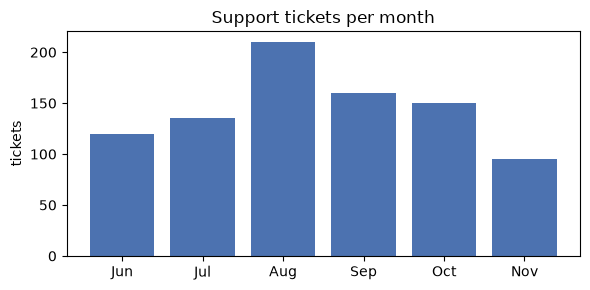

In [5]:
months = ["Jun", "Jul", "Aug", "Sep", "Oct", "Nov"]
tickets = [120, 135, 210, 160, 150, 95]

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(months, tickets, color="#4C72B0")
ax.set_title("Support tickets per month")
ax.set_ylabel("tickets")
fig.tight_layout()
buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=100)
(OUT / "tickets_chart.png").write_bytes(buffer.getvalue())
plt.show()

In [6]:
image_b64 = base64.standard_b64encode((OUT / "tickets_chart.png").read_bytes()).decode()

answer = chat(
    [{
        "role": "user",
        "content": [
            {"type": "image", "source": {"type": "base64", "media_type": "image/png", "data": image_b64}},
            {"type": "text", "text": "Which month had the most tickets, roughly how many, and what changed after it? Two sentences."},
        ],
    }],
    max_tokens=300,
    output_config={"effort": "low"},
)
print(answer)

August had the most tickets, at roughly 210. After that, volume fell to about 160 in September, then to about 150 in October, and dropped further to about 95 in November, the lowest of the period.


That's all for vision: the exam guide lists it as out of scope.

## 3. PDFs

A PDF goes in as a `document` block. Claude gets both the extracted text *and* an image of each page, so it can read charts and tables that text extraction would lose. To have something to send, the next cell writes a two-page report with matplotlib (text on page 1, a chart on page 2).

In [7]:
from matplotlib.backends.backend_pdf import PdfPages

plt.rcParams["pdf.fonttype"] = 42   # embed TrueType fonts, so the PDF's text can be extracted
report = [
    "Nimbus Robotics - Q3 2026 operations report",
    "",
    "Robots deployed: 412 (up from 365 in Q2). Average uptime was 98.1%, below the 99% target, "
    "because of a firmware fault in August that stopped 30 robots for two days.",
    "",
    "Customer support: ticket volume peaked in August with the firmware fault and fell back in September. "
    "The median time to first response was 3.2 hours.",
    "",
    "Next quarter: roll out firmware 5.2 with automatic rollback, and open a support desk in Lisbon.",
]
pdf_path = OUT / "q3_report.pdf"
with PdfPages(pdf_path) as pdf:
    page = plt.figure(figsize=(8.27, 11.69))            # A4
    y = 0.92
    for i, paragraph in enumerate(report):
        for line in textwrap.wrap(paragraph, 80) or [""]:
            page.text(0.08, y, line, fontsize=16 if i == 0 else 11, weight="bold" if i == 0 else "normal")
            y -= 0.03
    pdf.savefig(page)
    plt.close(page)

    page, ax = plt.subplots(figsize=(8.27, 5))
    ax.plot(["Q4 25", "Q1 26", "Q2 26", "Q3 26"], [97.2, 98.6, 99.1, 98.1], marker="o")
    ax.axhline(99, linestyle="--", color="grey")
    ax.set_title("Average robot uptime (%) per quarter; dashed line = 99% target")
    pdf.savefig(page)
    plt.close(page)

print(pdf_path, pdf_path.stat().st_size, "bytes")

outputs/q3_report.pdf 28007 bytes


In [8]:
pdf_b64 = base64.standard_b64encode(pdf_path.read_bytes()).decode()

answer = chat(
    [{
        "role": "user",
        "content": [
            {"type": "document", "source": {"type": "base64", "media_type": "application/pdf", "data": pdf_b64}},
            {"type": "text", "text": "Summarise this report in three bullet points. Then say in one sentence what the chart on page 2 shows."},
        ],
    }],
    max_tokens=500,
    output_config={"effort": "low"},
)
print(answer)

**Summary**

- **Deployment and uptime:** Nimbus deployed 412 robots in Q3 2026, up from 365 in Q2. Average uptime was 98.1%, short of the 99% target because an August firmware fault stopped 30 robots for two days.
- **Customer support:** Ticket volume peaked in August with the firmware fault and fell back in September. The median time to first response was 3.2 hours.
- **Next quarter:** The company plans to roll out firmware 5.2 with automatic rollback and open a support desk in Lisbon.

**Chart:** The chart shows average robot uptime by quarter, rising from about 97.2% in Q4 2025 to a peak of about 99.1% in Q2 2026 (the only quarter above the 99% target), then dropping to 98.1% in Q3 2026.


## 4. Citations

With `"citations": {"enabled": True}` on a document block, Claude's answer comes back split into several `text` blocks, and the blocks that state facts from the document carry a `citations` list. Each citation points at the exact passage it relies on: `cited_text`, which document (`document_index`, `document_title`) and where (character positions for plain text, page numbers for PDFs).

Why it matters: the user (or your code) can check every claim against the source. That's a reliability feature, not decoration.

In [9]:
policy = (
    "Returns policy. Customers can return unused products within 30 days of delivery for a full refund. "
    "Opened products can be returned within 14 days and get store credit instead of a refund. "
    "Return shipping is free for orders over 50 euros; below that, the customer pays 4.95 euros. "
    "Refunds are issued to the original payment method within 5 working days of the return arriving."
)

response = client.messages.create(
    model=model,
    max_tokens=600,
    output_config={"effort": "low"},
    messages=[{
        "role": "user",
        "content": [
            {
                "type": "document",
                "source": {"type": "text", "media_type": "text/plain", "data": policy},
                "title": "Returns policy",
                "citations": {"enabled": True},
            },
            {"type": "text", "text": "I opened a 40-euro kettle 10 days ago and don't like it. What can I get back, and what does shipping cost?"},
        ],
    }],
)

sources = []
answer = ""
for block in response.content:
    if block.type != "text":
        continue
    answer += block.text
    for citation in block.citations or []:
        sources.append(citation)
        answer += f" [{len(sources)}]"

print(answer, "\n")
for n, c in enumerate(sources, start=1):
    print(f"[{n}] {c.document_title}, characters {c.start_char_index}-{c.end_char_index}: \"{c.cited_text.strip()}\"")

Since you opened the kettle 10 days ago, you're still within the window for opened products. Opened products can be returned within 14 days and get store credit instead of a refund. [1] So you'd receive store credit, not money back to your card, and you have about 4 days left to send it back.

As for shipping, return shipping is free for orders over 50 euros; below that, the customer pays 4.95 euros. [2] Your kettle cost 40 euros, which is under that threshold, so you'd pay 4.95 euros for return shipping.

If the 40 euros was your whole order, that's the figure that matters. If the kettle was part of a larger order totaling over 50 euros, the policy's wording ("orders over 50 euros") suggests shipping could be free, but the policy doesn't say explicitly, so it's worth confirming with the store. 

[1] Returns policy, characters 99-188: "Opened products can be returned within 14 days and get store credit instead of a refund."
[2] Returns policy, characters 188-280: "Return shipping is fr

> **Good to know.** Citations can't be combined with structured outputs (`output_config.format`): the request returns a 400, because the cited answer has to be free text split into blocks. If you need both, get the cited answer first, then extract the structure in a second call, or ask for the source passages inside your own JSON schema.

**Exam angle (Domain 5).** When a system summarises or merges several sources, keep each claim linked to where it came from: citations, or a source label carried with every chunk (as in 2.7). The guide treats "lost provenance" as a reliability failure.

## 5. Prompt caching

Every request makes Claude process the whole prompt again. If many requests start with the same long text (a big system prompt, a document, tool definitions, the conversation so far), **prompt caching** lets the API reuse the work from an earlier request:

- You mark the end of the reusable part with `cache_control: {"type": "ephemeral"}`. Everything **before and including** that block is the cached **prefix**, in the order `tools` → `system` → `messages`.
- It is an **exact prefix match**: change one character before the marker (a timestamp in the system prompt, a reordered tool) and the cache misses.
- Writing to the cache costs a little more than normal input (1.25×); reading from it costs a small fraction (0.1× of the input price on most models, 0.05× on Sonnet 5.5 at current prices).
- An entry lives **5 minutes** by default, and every hit resets the timer. `"ttl": "1h"` keeps it an hour, at a higher write price.
- Up to **4** markers per request. Prompts shorter than the model's **minimum** (512 tokens on Sonnet 5.5, per the [prompt caching docs](https://platform.claude.com/docs/en/build-with-claude/prompt-caching)) are silently not cached: no error, just zeros in `usage`.

The demo: a product catalogue of about 3,000 tokens as the system prompt, then two different questions.

In [10]:
colours = ["black", "white", "red", "blue", "green"]
catalogue_lines = ["You answer customer questions about the Nimbus Home product catalogue below. Be brief and quote prices exactly.", ""]
for i in range(40):
    catalogue_lines.append(
        f"Product X{100 + i * 10}: a {'waterproof ' if i % 3 == 0 else ''}{['robot vacuum', 'drone', 'smart speaker', 'garden sensor'][i % 4]} "
        f"in {colours[i % 5]}, price {49 + i * 7} euros, warranty {1 + i % 3} years, battery {2 + i % 5} hours, "
        f"weight {round(0.4 + i * 0.15, 2)} kg, ships in {1 + i % 4} days. "
        f"Includes {['a charging dock', 'two spare filters', 'a carry case', 'a wall mount'][i % 4]} and a quick-start guide."
    )
CATALOGUE = "\n".join(catalogue_lines)

system = [{"type": "text", "text": CATALOGUE, "cache_control": {"type": "ephemeral"}}]
count = client.messages.count_tokens(model=model, system=system, messages=[{"role": "user", "content": "hi"}])
print("prompt size:", count.input_tokens, "tokens (minimum to cache on Sonnet 5.5: 512)")

prompt size: 3001 tokens (minimum to cache on Sonnet 5.5: 512)


In [11]:
def ask_catalogue(question):
    response = client.messages.create(
        model=model,
        max_tokens=300,
        output_config={"effort": "low"},   # keep thinking/effort identical between requests that share a cache
        system=system,
        messages=[{"role": "user", "content": question}],
    )
    u = response.usage
    print(f"Q: {question}")
    print(f"   cache write: {u.cache_creation_input_tokens:5}   cache read: {u.cache_read_input_tokens:5}   uncached input: {u.input_tokens:4}")
    print("   A:", textwrap.shorten(text_of(response), 200))


ask_catalogue("Which waterproof drones do you sell, and at what price?")
ask_catalogue("What's the warranty on the X200?")

Q: Which waterproof drones do you sell, and at what price?
   cache write:  2993   cache read:     0   uncached input:   24
   A: We sell four waterproof drones: - **X190**: green, 112 euros, 1-year warranty, 6-hour battery - **X310**: white, 196 euros, 1-year warranty, 3-hour battery - **X430**: blue, 280 euros, 1-year [...]


Q: What's the warranty on the X200?
   cache write:     0   cache read:  2993   uncached input:   17
   A: The X200 (smart speaker in black, 119 euros) has a 2-year warranty.


The first request **wrote** the catalogue to the cache; the second, with a different question, **read** it. Only the question itself was processed at the full price. (If you re-run these cells within 5 minutes, both requests read from the cache.)

**Exam angle (Domain 5, and 4 for batch work).** Two cost tools that are easy to confuse:

| | Prompt caching | Message Batches API |
|---|---|---|
| Saves on | the repeated **prefix** of many requests (reads at a fraction of the input price) | **every** token, input and output: 50% off |
| Timing | normal requests, answered right away | asynchronous: results within 24 hours, no latency guarantee |
| Fits | chat with a long system prompt, many questions on one document, agent loops | overnight jobs, evals, bulk extraction where nobody waits for the answer |

They combine: a batch of requests sharing a prefix can use both. And the classic caching bug is a value that changes on every request (a timestamp, a request id, unsorted JSON) placed *before* the cache marker.

## 6. Built-in extras

### Code execution tool

Some tools run on **Anthropic's servers** instead of in your code ("server tools"). With the code execution tool, Claude can write and run Python in a sandbox (no internet access) and use the output in its answer. You only declare it; there's no function to implement and no tool loop to write: the code, its output and the answer all come back in one response.

> **Changed since the course.** The tool's `type` is versioned by date. The current version is `code_execution_20260521`; older notebooks may use an earlier date or need a beta header.

In [12]:
response = client.messages.create(
    model=model,
    max_tokens=2000,
    tools=[{"type": "code_execution_20260521", "name": "code_execution"}],
    messages=[{
        "role": "user",
        "content": "Use Python to simulate 100,000 rolls of two dice (seed 42). Report how often a sum of 7 came up, "
                   "and compare it with the exact probability. Keep the answer to three sentences.",
    }],
)

for block in response.content:
    if block.type == "server_tool_use":
        source = block.input.get("code") or block.input.get("command") or json.dumps(block.input)
        print(f"[{block.type}: {block.name}]\n" + textwrap.indent(str(source)[:1200], "    "))
    elif block.type.endswith("tool_result"):
        stdout = getattr(block.content, "stdout", None)
        print(f"[{block.type}]" + ("\n" + textwrap.indent(stdout[:800], "    ") if stdout else ""))
    elif block.type == "text":
        print(block.text)
print("\nstop_reason:", response.stop_reason)

[server_tool_use: bash_code_execution]
    python3 -c "
    import random
    random.seed(42)
    n=100000
    c=sum(random.randint(1,6)+random.randint(1,6)==7 for _ in range(n))
    print(c,c/n,1/6)
    import numpy as np
    r=np.random.default_rng(42)
    s=r.integers(1,7,n)+r.integers(1,7,n)
    print((s==7).sum(),(s==7).mean())
    "
[bash_code_execution_tool_result]
    16456 0.16456 0.16666666666666666
    16884 0.16884

Using Python's `random` module with seed 42, a sum of 7 came up 16,456 times in 100,000 rolls, which is 16.456%. The exact probability is 6/36 = 1/6 ≈ 16.667%, which would give about 16,667 sevens. The simulation came in about 0.21 percentage points (211 rolls) low, well within normal random variation, since the standard error is about 118 rolls.

stop_reason: end_turn


### Files API

Base64 means sending the whole file in every request. The **Files API** uploads a file once and gives you a `file_id` to reference in any later request (until you delete it). Uploading, listing and deleting are free; the content is billed as input tokens when a request uses it.

> **Changed since the course.** The Files API was in beta (`client.beta.files` and a `betas=["files-api-..."]` header). It is generally available now: `client.files.*`, and a `{"type": "file", "file_id": ...}` source works in a normal `client.messages.create`.

In [13]:
uploaded = client.files.upload(file=("q3_report.pdf", pdf_path.read_bytes(), "application/pdf"))
print("uploaded:", uploaded.filename, uploaded.mime_type, uploaded.size_bytes, "bytes")

answer = chat(
    [{
        "role": "user",
        "content": [
            {"type": "document", "source": {"type": "file", "file_id": uploaded.id}},
            {"type": "text", "text": "What uptime did the robots reach in Q3, and why did it miss the target? One sentence."},
        ],
    }],
    max_tokens=200,
    output_config={"effort": "low"},
)
print(answer)

client.files.delete(uploaded.id)        # files persist until deleted
print("deleted")

uploaded: q3_report.pdf application/pdf 28007 bytes


Robots averaged 98.1% uptime in Q3, missing the 99% target because an August firmware fault stopped 30 robots for two days.


deleted


## Recap

- **Thinking** is adaptive on current models: steer it with `output_config.effort`; `budget_tokens` (the course's way) returns a 400. Read answers from `text` blocks and pass thinking blocks back unchanged.
- **Images** (out of exam scope) and **PDFs** are content blocks; PDFs give Claude both text and page images.
- **Citations** tie each claim to a passage of the source; they can't be combined with `output_config.format`.
- **Prompt caching** reuses an identical prefix: mark it with `cache_control`, check `cache_creation_input_tokens` / `cache_read_input_tokens`, mind the minimum length, the 5-minute TTL and anything that changes the prefix. Batches are the other cost tool (50% off, asynchronous).
- **Server tools** like code execution run on Anthropic's side; the **Files API** uploads once and references by id.

Next: [2.9 Model Context Protocol](09-model-context-protocol.ipynb).